In [4]:
import csv

with open("../data/raw/ott_data.csv", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)

    header = next(reader, None)

    if header is None:
        print("CSV file is empty!")
    else:
        print("Columns:", header)

        for i, row in enumerate(reader):
            if i < 5:
                print(row)

Columns: ['Viewer_ID', 'Subscription_Plan', 'Device_Type', 'City', 'Content_Genre', 'Age', 'Weekly_Watch_Hours', 'Titles_Watched', 'Avg_Session_Minutes', 'Last_Active_Date', 'Engagement_Score']
['V1238', 'Mobile', 'Smart_TV', 'Lucknow', 'Thriller', '25', '13.4', '13', '94', '2026-04-21', '69.6']
['V1247', 'Mobile', 'Smartphone', 'Jaipur', 'Action', '32', '5.8', '9', '80', '2025-11-10', '67.1']
['V1144', 'Mobile', 'Smartphone', 'Bengaluru', 'Documentary', '34', '2.1', '16', '76', '2024-12-10', '54.3']
['V1127', 'Standard', 'Smartphone', 'Lucknow', 'Comedy', '22', '7.6', '19', '79', '2025-08-08', '70.0']
['V1098', 'Standard', 'Laptop', 'Lucknow', 'Action', '33', '12.9', '1', '51', '2024-12-28', '44.4']


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

# Plot style
sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv("../data/raw/ott_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])
df.isnull().sum().sum()
(df.isnull().mean()*100).round(2)
df.duplicated().sum()
df[df.duplicated()]

Dataset shape: (255, 11)
Number of rows: 255
Number of columns: 11


,Viewer_ID,Subscription_Plan,Device_Type,City,Content_Genre,Age,Weekly_Watch_Hours,Titles_Watched,Avg_Session_Minutes,Last_Active_Date,Engagement_Score
128,V1093,Basic,Smartphone,Delhi,Documentary,41.0,17.2,15,85.0,2026-08-30,80.5
135,V1214,Basic,Tablet,Delhi,Documentary,25.0,5.2,10,68.0,2026-03-14,52.5
141,V1039,Basic,Smart_TV,Bengaluru,Action,23.0,8.7,6,56.0,2026-07-19,45.3
177,V1031,Standard,Laptop,Mumbai,Drama,33.0,12.0,11,54.0,2026-07-21,79.8
208,V1004,Standard,Smartphone,Delhi,Drama,22.0,9.8,13,43.0,2026-10-13,50.7


In [8]:
print("City:")
print(df["City"].unique())

print("\nSubscription Plan :")
print(df["Subscription_Plan"].unique())

print("\nDevice Type:")
print(df["Device_Type"].unique())

print("\nContent Genre :")
print(df["Content_Genre"].unique())

City:
<StringArray>
['Lucknow', 'Jaipur', 'Bengaluru', 'Mumbai', 'Delhi', 'Lucknow  ', 'mumbai', nan, ' Mumbai ', ' Lucknow ', ' Jaipur ']
Length: 11, dtype: str

Subscription Plan :
<StringArray>
['Mobile', 'Standard', 'Basic', 'Premium']
Length: 4, dtype: str

Device Type:
<StringArray>
['Smart_TV', 'Smartphone', 'Laptop', 'Tablet']
Length: 4, dtype: str

Content Genre :
<StringArray>
['Thriller', 'Action', 'Documentary', 'Comedy', 'Drama', nan]
Length: 6, dtype: str


In [9]:
df_row =df.copy()

In [10]:
# Creating a backup of the original dataset

df_raw = df.copy()

print("Backup created successfully!")
print("Original dataset shape:", df_raw.shape)
# Checking duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Backup created successfully!
Original dataset shape: (255, 11)
Number of duplicate rows: 5


In [14]:
# Display duplicate records

df[df.duplicated()]

,Viewer_ID,Subscription_Plan,Device_Type,City,Content_Genre,Age,Weekly_Watch_Hours,Titles_Watched,Avg_Session_Minutes,Last_Active_Date,Engagement_Score
128,V1093,Basic,Smartphone,Delhi,Documentary,41.0,17.2,15,85.0,2026-08-30,80.5
135,V1214,Basic,Tablet,Delhi,Documentary,25.0,5.2,10,68.0,2026-03-14,52.5
141,V1039,Basic,Smart_TV,Bengaluru,Action,23.0,8.7,6,56.0,2026-07-19,45.3
177,V1031,Standard,Laptop,Mumbai,Drama,33.0,12.0,11,54.0,2026-07-21,79.8
208,V1004,Standard,Smartphone,Delhi,Drama,22.0,9.8,13,43.0,2026-10-13,50.7


In [11]:
# Removing duplicate records

df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Shape after removing duplicates:", df.shape)

Duplicates removed successfully!
Shape after removing duplicates: (250, 11)


In [28]:
# 1. Verify duplicate removal
print("Remaining duplicate rows:", df.duplicated().sum())

# 2. Check true categorical columns
categorical_columns = [
    "City",
    "Subscription_Plan",
    "Device_Type"
]

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))

# 3. Check numeric and date columns separately
print("\nEngagement Score Summary:")
print(df["Engagement_Score"].describe())



Remaining duplicate rows: 0

Column: City
City
Delhi        69
Mumbai       63
Bengaluru    51
Lucknow      35
Jaipur       25
Lucknow       3
mumbai        1
 Mumbai       1
 Lucknow      1
 Jaipur       1
Name: count, dtype: int64

Column: Subscription_Plan
Subscription_Plan
Standard    86
Basic       70
Mobile      52
Premium     42
Name: count, dtype: int64

Column: Device_Type
Device_Type
Smartphone    105
Smart_TV       74
Laptop         50
Tablet         21
Name: count, dtype: int64

Engagement Score Summary:
count    250.000000
mean      55.264400
std       14.225741
min       17.400000
25%       45.325000
50%       54.700000
75%       64.600000
max      100.000000
Name: Engagement_Score, dtype: float64


In [27]:
# Removing extra spaces and standardizing text case

for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip().str.lower()

    # Checking categorical values after standardization

    # Checking categorical values after standardization

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))



Column: City
City
mumbai       65
delhi        63
bengaluru    51
lucknow      39
jaipur       26
<NA>          6
Name: count, dtype: Int64

Column: Subscription_Plan
Subscription_Plan
standard    86
basic       70
mobile      52
premium     42
Name: count, dtype: Int64

Column: Device_Type
Device_Type
smartphone    105
smart_tv       74
laptop         50
tablet         21
Name: count, dtype: Int64

Column: Engagement_Score
Engagement_Score
55.6    3
64.6    3
54.2    3
55.9    3
52.1    3
       ..
66.8    1
30.9    1
57.2    1
60.3    1
46.0    1
Name: count, Length: 198, dtype: Int64


In [14]:
# Selecting numerical columns

numeric_columns = [
    "Age",
    "Weekly_Watch_Hours",
    "Titles_Watched",
    "Avg_Session_Minutes",
    "Last_Activity_Date",
    "Engagement_Score"
]

print(numeric_columns)

['Age', 'Weekly_Watch_Hours', 'Titles_Watched', 'Avg_Session_Minutes', 'Last_Activity_Date', 'Engagement_Score']


In [15]:
 # Automatically select existing numeric columns (avoids missing or date columns)
numeric_columns = df.select_dtypes(include="number").columns

# Checking minimum and maximum values of numerical columns
display(df[numeric_columns].agg(["min", "max"]).T)

# Checking invalid age values (adjust 0 and 100 to your exact required bounds)
invalid_age = df[(df["Age"] < 0) | (df["Age"] > 100)]

display(invalid_age)
print("Invalid age values:", len(invalid_age))

,min,max
Age,-26.0,212.0
Weekly_Watch_Hours,1.1,23.0
Titles_Watched,1.0,22.0
Avg_Session_Minutes,10.0,103.0
Engagement_Score,17.4,100.0


,Viewer_ID,Subscription_Plan,Device_Type,City,Content_Genre,Age,Weekly_Watch_Hours,Titles_Watched,Avg_Session_Minutes,Last_Active_Date,Engagement_Score
184,V1038,Standard,Smart_TV,Lucknow,Drama,212.0,18.2,10,42.0,2026-08-24,83.2
228,V1193,Mobile,Smart_TV,Lucknow,Drama,-26.0,6.0,13,34.0,2025-12-12,41.2


Invalid age values: 2


In [16]:
# Clean column names to remove accidental leading/trailing spaces
df.columns = df.columns.str.strip()

# Checking invalid values in each numerical column
invalid_ranges = {
    "Age": (18, 58),
    "Weekly_Watch_Hours": (1.1, 23.0),
    "Titles_Watched": (1, 22),
    "Avg_Session_Minutes": (10, 103),
    "Engagement_Score": (17.4, 100),
}

for column, (minimum, maximum) in invalid_ranges.items():
  if column not in df.columns:
    print(
        f"Warning: Column '{column}' not found in DataFrame. Available"
        f" columns: {list(df.columns)}"
    )
    continue

  # Ensure the column is numeric before comparing (non-numeric values become NaN)
  series = pd.to_numeric(df[column], errors="coerce")

  invalid = df[(series < minimum) | (series > maximum)]

  print(
      f"{column} | Invalid count: {len(invalid)} | Minimum allowed: {minimum} |"
      f" Maximum allowed: {maximum}"
  )
  

Age | Invalid count: 24 | Minimum allowed: 18 | Maximum allowed: 58
Weekly_Watch_Hours | Invalid count: 0 | Minimum allowed: 1.1 | Maximum allowed: 23.0
Titles_Watched | Invalid count: 0 | Minimum allowed: 1 | Maximum allowed: 22
Avg_Session_Minutes | Invalid count: 0 | Minimum allowed: 10 | Maximum allowed: 103
Engagement_Score | Invalid count: 0 | Minimum allowed: 17.4 | Maximum allowed: 100


In [42]:
# Example pattern: marking invalid Age values as missing

df.loc[
    (df["Age"] < 18) | (df["Age"] > 72),
    "Age"
] = np.nan
# Checking missing values in each column

missing_count = df.isnull().sum()

print(missing_count)

# Percentage of missing values in each column

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print(missing_percentage)

Viewer_ID               0
Subscription_Plan       0
Device_Type             0
City                    6
Content_Genre           5
Age                    29
Weekly_Watch_Hours      0
Titles_Watched          0
Avg_Session_Minutes     4
Last_Active_Date        0
Engagement_Score        0
dtype: int64
Viewer_ID               0.0
Subscription_Plan       0.0
Device_Type             0.0
City                    2.4
Content_Genre           2.0
Age                    11.6
Weekly_Watch_Hours      0.0
Titles_Watched          0.0
Avg_Session_Minutes     1.6
Last_Active_Date        0.0
Engagement_Score        0.0
dtype: float64


In [17]:
# Display rows that contain at least one missing value

df[df.isnull().any(axis=1)]

,Viewer_ID,Subscription_Plan,Device_Type,City,Content_Genre,Age,Weekly_Watch_Hours,Titles_Watched,Avg_Session_Minutes,Last_Active_Date,Engagement_Score
29,V1030,Premium,Tablet,Delhi,NaN,29.0,5.0,14,60.0,2025-04-17,56.1
38,V1241,Standard,Laptop,Bengaluru,Action,36.0,7.6,8,NaN,2025-05-31,59.4
47,V1158,Basic,Smartphone,Mumbai,Drama,NaN,7.6,15,75.0,2025-12-06,52.8
62,V1120,Premium,Smartphone,NaN,Documentary,31.0,16.1,8,70.0,2026-01-25,49.5
66,V1059,Mobile,Laptop,Bengaluru,Action,35.0,7.5,10,NaN,2025-12-24,63.3
87,V1116,Premium,Smartphone,NaN,Thriller,28.0,8.0,17,64.0,2026-07-18,69.3
103,V1074,Standard,Laptop,Jaipur,Thriller,26.0,9.6,13,NaN,2026-03-15,45.4
149,V1009,Basic,Laptop,NaN,Comedy,32.0,1.5,9,49.0,2026-10-02,21.5
158,V1229,Premium,Smart_TV,Delhi,NaN,29.0,7.3,11,40.0,2026-11-11,61.3
162,V1001,Premium,Smartphone,NaN,Thriller,44.0,6.4,15,45.0,2025-03-27,48.8


In [44]:
# Missing values in categorical columns

df[categorical_columns].isnull().sum()

City                 6
Subscription_Plan    0
Device_Type          0
Engagement_Score     0
dtype: int64

In [18]:
# Example: filling missing Age values with the median

age_median = df["Age"].median()

df["Age"] = df["Age"].fillna(age_median)

print("Missing Age values filled.")

Missing Age values filled.


In [20]:
# Example: filling missing City values using the mode

city_mode = df["City"].mode()[0]

df["City"] = df["City"].fillna(city_mode)

print("Missing City values filled.")



Missing City values filled.


In [19]:
# Clean accidental leading/trailing spaces in column names
df.columns = df.columns.str.strip()

# Find any column matching 'last_activity_date' regardless of spaces or case
matching_cols = [
    col
    for col in df.columns
    if col.lower().replace(" ", "_") == "last_activity_date"
]

if matching_cols:
  col_name = matching_cols[0]
  df[col_name] = pd.to_datetime(df[col_name], errors="coerce")
  print("Date conversion completed!")
  print(f"Column '{col_name}' dtype:", df[col_name].dtype)
else:
  print("Column 'Last_Activity_Date' not found. Available columns in df:")
  print(df.columns.tolist())

Column 'Last_Activity_Date' not found. Available columns in df:
['Viewer_ID', 'Subscription_Plan', 'Device_Type', 'City', 'Content_Genre', 'Age', 'Weekly_Watch_Hours', 'Titles_Watched', 'Avg_Session_Minutes', 'Last_Active_Date', 'Engagement_Score']


In [25]:
print("Dataset Loaded Successfully!")
print(df.head())


# Convert Engagement_Score into numeric values

df["Engagement_Score"] = pd.to_numeric(
    df["Engagement_Score"],
    errors="coerce"
)

# Create Engagement Category

df["Engagement_Category"] = pd.cut(
    df["Engagement_Score"],
    bins=[0, 40, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# Display results

print(df[["Engagement_Score", "Engagement_Category"]].head(10))

# Count categories

print("\nEngagement Category Count:")
print(df["Engagement_Category"].value_counts())

# Calculate percentages

print("\nEngagement Category Percentage:")
print(
    df["Engagement_Category"].value_counts(normalize=True) * 100
)




# Treat negative ages and ages above 120 as invalid

valid_age = df["Age"].where(
    df["Age"].between(0, 120)
)

df["Age_Group"] = pd.cut(
    valid_age,
    bins=[0, 18, 26, 36, 51, 121],
    labels=["Under 18", "18-25", "26-35", "36-50", "51-120"],
    right=False
)


df["Watch_Hours_Per_Title"] = (
    df["Weekly_Watch_Hours"] /
    df["Titles_Watched"].replace(0, pd.NA)
)

df["Last_Active_Date"] = pd.to_datetime(
    df["Last_Active_Date"],
    errors="coerce"
)



print("\nFirst Five Rows:")
print(df.head())




print("\nEngagement Category Count:")

print(
    df["Engagement_Category"].value_counts()
)




print("\nEngagement Category Percentage:")

print(
    df["Engagement_Category"].value_counts(
        normalize=True
    ) * 100
)




new_columns = [
    "Watch_Hours_Per_Title",
    "Age_Group",
    "Engagement_Category"
]

print("\nNew Features:")

print(df[new_columns].head(10))




print("\nTotal rows:", df.shape[0])

print("Total columns:", df.shape[1])

print("\nColumn Names:")

print(df.columns.tolist())




print("\nMissing Values in New Features:")

print(df[new_columns].isnull().sum())

print("\nMissing Values in Complete Dataset:")

print(df.isnull().sum())




print("\nTotal Duplicate Rows:")

print(df.duplicated().sum())

print("\nDuplicate Viewer IDs:")

print(df["Viewer_ID"].duplicated().sum())











print("\nStatistical Summary:")

print(df.describe())



categorical_columns = [
    "Subscription_Plan",
    "Device_Type",
    "City",
    "Content_Genre",
    "Age_Group",
    "Engagement_Category"
]

for column in categorical_columns:

    print("\n---", column, "---")

    print(df[column].value_counts())



print("\nSubscription Plan Distribution:")

print(df["Subscription_Plan"].value_counts())



print("\nDevice Type Distribution:")

print(df["Device_Type"].value_counts())



print("\nContent Genre Distribution:")

print(df["Content_Genre"].value_counts())



print("\nAverage Weekly Watch Hours:")

print(df["Weekly_Watch_Hours"].mean())




print("\nAverage Engagement Score:")

print(df["Engagement_Score"].mean())



print("\nFinal Dataset:")

print(df.head(10))

print("\nFinal Dataset Shape:")

print(df.shape)

Dataset Loaded Successfully!
  Viewer_ID Subscription_Plan Device_Type       City Content_Genre   Age  Weekly_Watch_Hours  Titles_Watched  Avg_Session_Minutes Last_Active_Date  Engagement_Score Engagement_Category Age_Group  Watch_Hours_Per_Title
0     V1238            Mobile    Smart_TV    Lucknow      Thriller  25.0                13.4              13                 94.0       2026-04-21              69.6              Medium     18-25               1.030769
1     V1247            Mobile  Smartphone     Jaipur        Action  32.0                 5.8               9                 80.0       2025-11-10              67.1              Medium     26-35               0.644444
2     V1144            Mobile  Smartphone  Bengaluru   Documentary  34.0                 2.1              16                 76.0       2024-12-10              54.3              Medium     26-35               0.131250
3     V1127          Standard  Smartphone    Lucknow        Comedy  22.0                 7.6       

In [70]:

import pandas as pd
import numpy as np
import os



input_file = "../data/raw/ott_data.csv"

output_file = "../data/processed/ott_data_clean.csv"

df = pd.read_csv(input_file)

print("Original Dataset Loaded Successfully!")
print("Original Shape:", df.shape)



text_columns = [
    "Subscription_Plan",
    "Device_Type",
    "City",
    "Content_Genre"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()


# Standardize category names

for col in ["Subscription_Plan", "City", "Content_Genre"]:
    df[col] = df[col].str.title()

df["Device_Type"] = (
    df["Device_Type"]
    .str.lower()
    .replace({"smart_tv": "Smart_TV"})
    .str.title()
    .replace({"Smart_Tv": "Smart_TV"})
)




numeric_columns = [
    "Age",
    "Weekly_Watch_Hours",
    "Titles_Watched",
    "Avg_Session_Minutes",
    "Engagement_Score"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )




df["Last_Active_Date"] = pd.to_datetime(
    df["Last_Active_Date"],
    errors="coerce"
)




before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("\nDuplicate Rows Removed:", before - after)




df.loc[
    ~df["Age"].between(0, 120),
    "Age"
] = np.nan

df["Age"] = df["Age"].fillna(
    df["Age"].median()
)



df["Avg_Session_Minutes"] = (
    df["Avg_Session_Minutes"].fillna(
        df["Avg_Session_Minutes"].median()
    )
)

df["City"] = df["City"].fillna("Unknown")

df["Content_Genre"] = (
    df["Content_Genre"].fillna("Unknown")
)



df["Engagement_Category"] = pd.cut(
    df["Engagement_Score"],
    bins=[0, 40, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)




df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 26, 36, 51, 121],
    labels=[
        "Under 18",
        "18-25",
        "26-35",
        "36-50",
        "51-120"
    ],
    right=False
)



df["Watch_Hours_Per_Title"] = (
    df["Weekly_Watch_Hours"] /
    df["Titles_Watched"].replace(0, np.nan)
)



df.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d"
)

print("\nCleaned Dataset Generated Successfully!")

print("Saved File:", os.path.abspath(output_file))



print("\nFinal Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst Five Rows:")
print(df.head())




if os.path.exists(output_file):

    print("\nFile Successfully Created!")

    cleaned_df = pd.read_csv(output_file)

    print("Verified Rows:", cleaned_df.shape[0])
    print("Verified Columns:", cleaned_df.shape[1])

else:

    print("File Creation Failed!")


Original Dataset Loaded Successfully!
Original Shape: (255, 11)

Duplicate Rows Removed: 5

Cleaned Dataset Generated Successfully!
Saved File: c:\Users\Win 10\OneDrive\Documents\HCL Project\data\processed\ott_data_clean.csv

Final Dataset Shape:
(250, 14)

Missing Values:
Viewer_ID                0
Subscription_Plan        0
Device_Type              0
City                     0
Content_Genre            0
Age                      0
Weekly_Watch_Hours       0
Titles_Watched           0
Avg_Session_Minutes      0
Last_Active_Date         0
Engagement_Score         0
Engagement_Category      0
Age_Group                0
Watch_Hours_Per_Title    0
dtype: int64

First Five Rows:
  Viewer_ID Subscription_Plan Device_Type       City Content_Genre   Age  Weekly_Watch_Hours  Titles_Watched  Avg_Session_Minutes Last_Active_Date  Engagement_Score Engagement_Category Age_Group  Watch_Hours_Per_Title
0     V1238            Mobile    Smart_TV    Lucknow      Thriller  25.0                13.4       

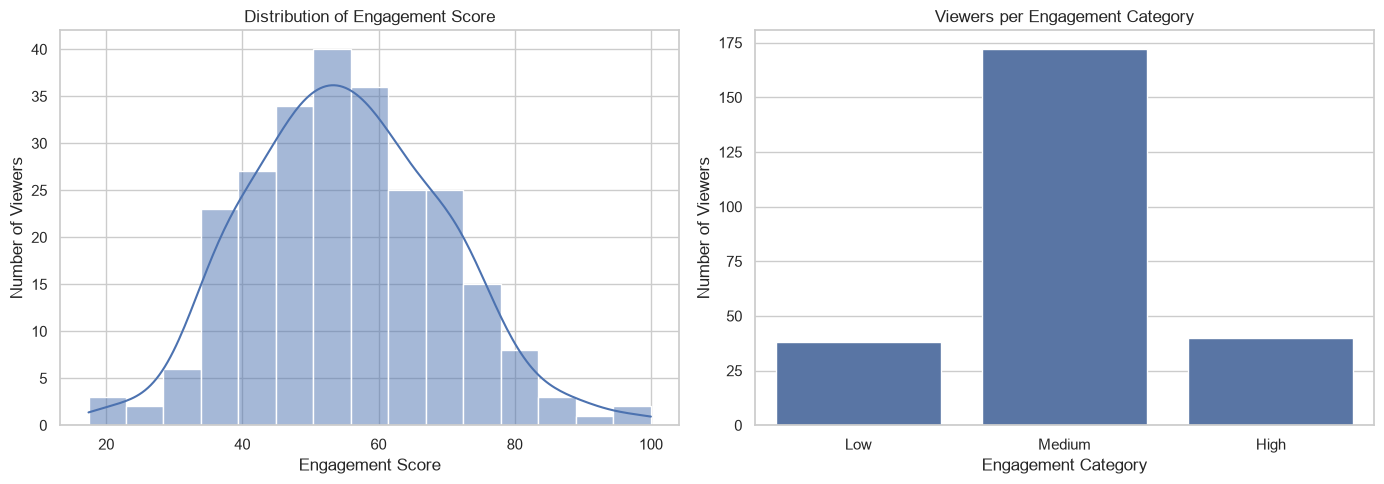

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of Engagement Score
sns.histplot(
    df["Engagement_Score"],
    bins=15,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Engagement Score")
axes[0].set_xlabel("Engagement Score")
axes[0].set_ylabel("Number of Viewers")

# Count of Engagement Categories
sns.countplot(
    data=df,
    x="Engagement_Category",
    order=["Low", "Medium", "High"],
    ax=axes[1]
)

axes[1].set_title("Viewers per Engagement Category")
axes[1].set_xlabel("Engagement Category")
axes[1].set_ylabel("Number of Viewers")

plt.tight_layout()

plt.savefig(
    "01_overall_satisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

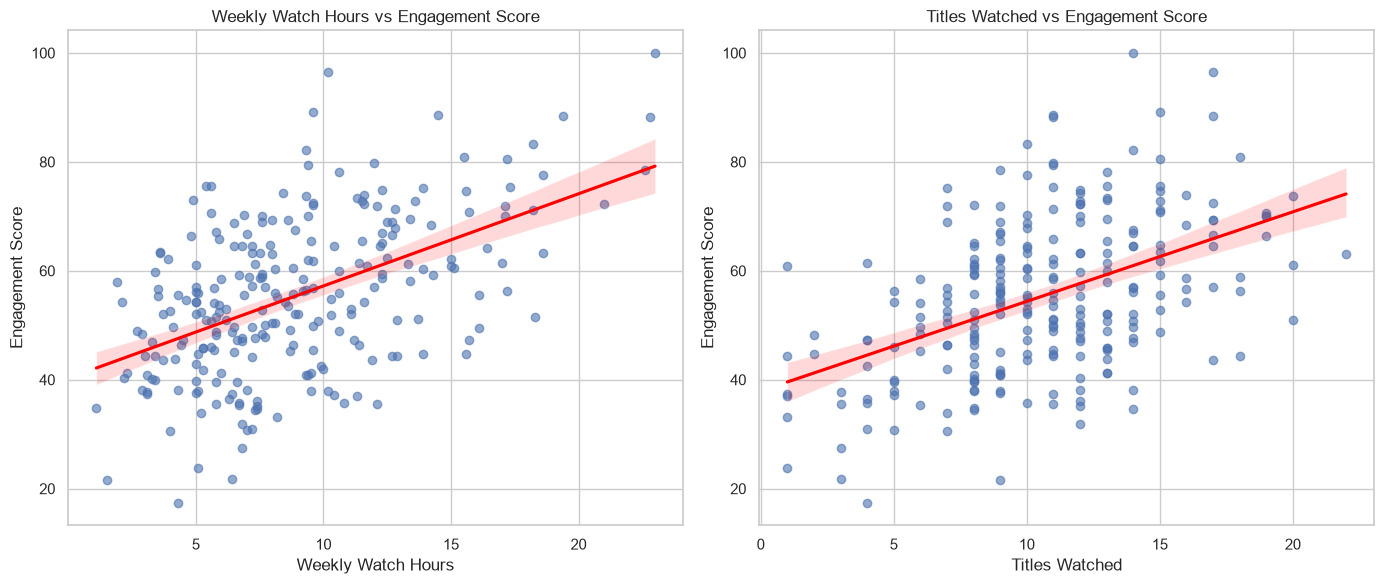

Graph saved successfully!
File location: c:\Users\Win 10\OneDrive\Documents\HCL Project\notebooks\02_balance_transactions.png


In [71]:



# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graph 1: Weekly Watch Hours vs Engagement Score
sns.regplot(
    data=df,
    x="Weekly_Watch_Hours",
    y="Engagement_Score",
    ax=axes[0],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

axes[0].set_title(
    "Weekly Watch Hours vs Engagement Score"
)
axes[0].set_xlabel("Weekly Watch Hours")
axes[0].set_ylabel("Engagement Score")


# Graph 2: Titles Watched vs Engagement Score
sns.regplot(
    data=df,
    x="Titles_Watched",
    y="Engagement_Score",
    ax=axes[1],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

axes[1].set_title(
    "Titles Watched vs Engagement Score"
)
axes[1].set_xlabel("Titles Watched")
axes[1].set_ylabel("Engagement Score")


# Adjust layout
plt.tight_layout()

# Save graph as PNG file
output_file = os.path.abspath(
    "02_balance_transactions.png"
)

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    format="png"
)

# Display graph
plt.show()

# Confirm file creation
print("Graph saved successfully!")
print("File location:", output_file)

plt.close(fig)


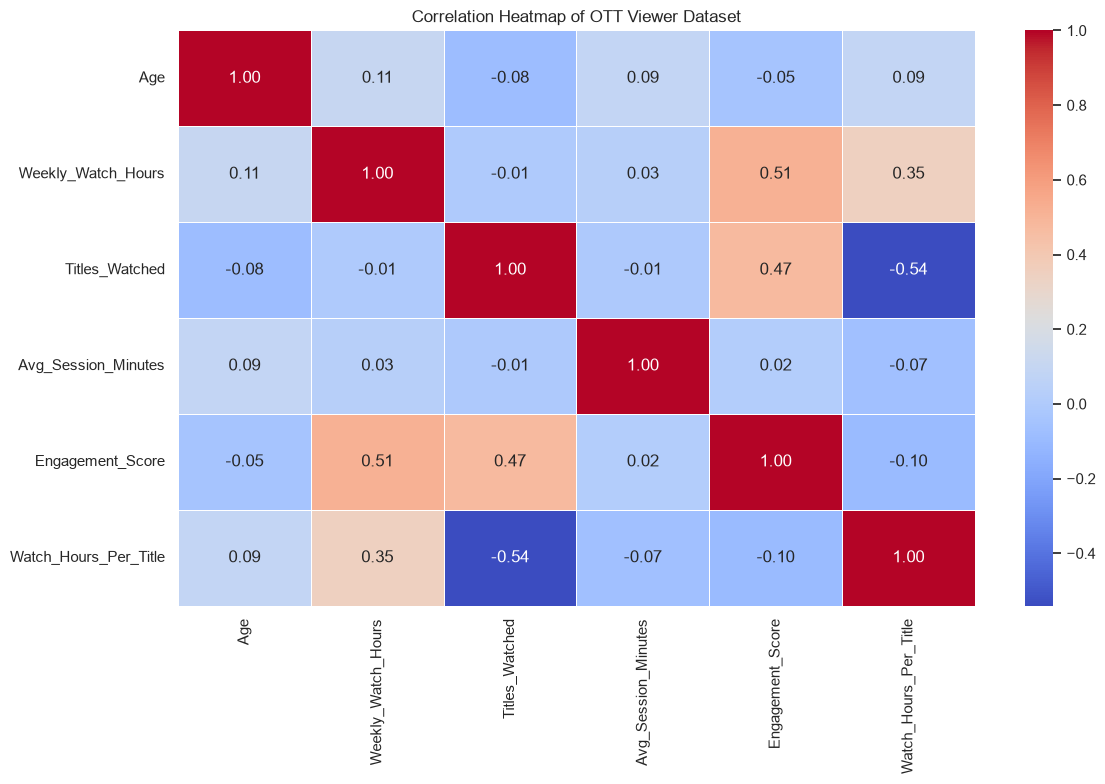

In [68]:
numeric_df = df.select_dtypes(
    include=["number"]
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of OTT Viewer Dataset")

plt.tight_layout()

plt.savefig(
    "03_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

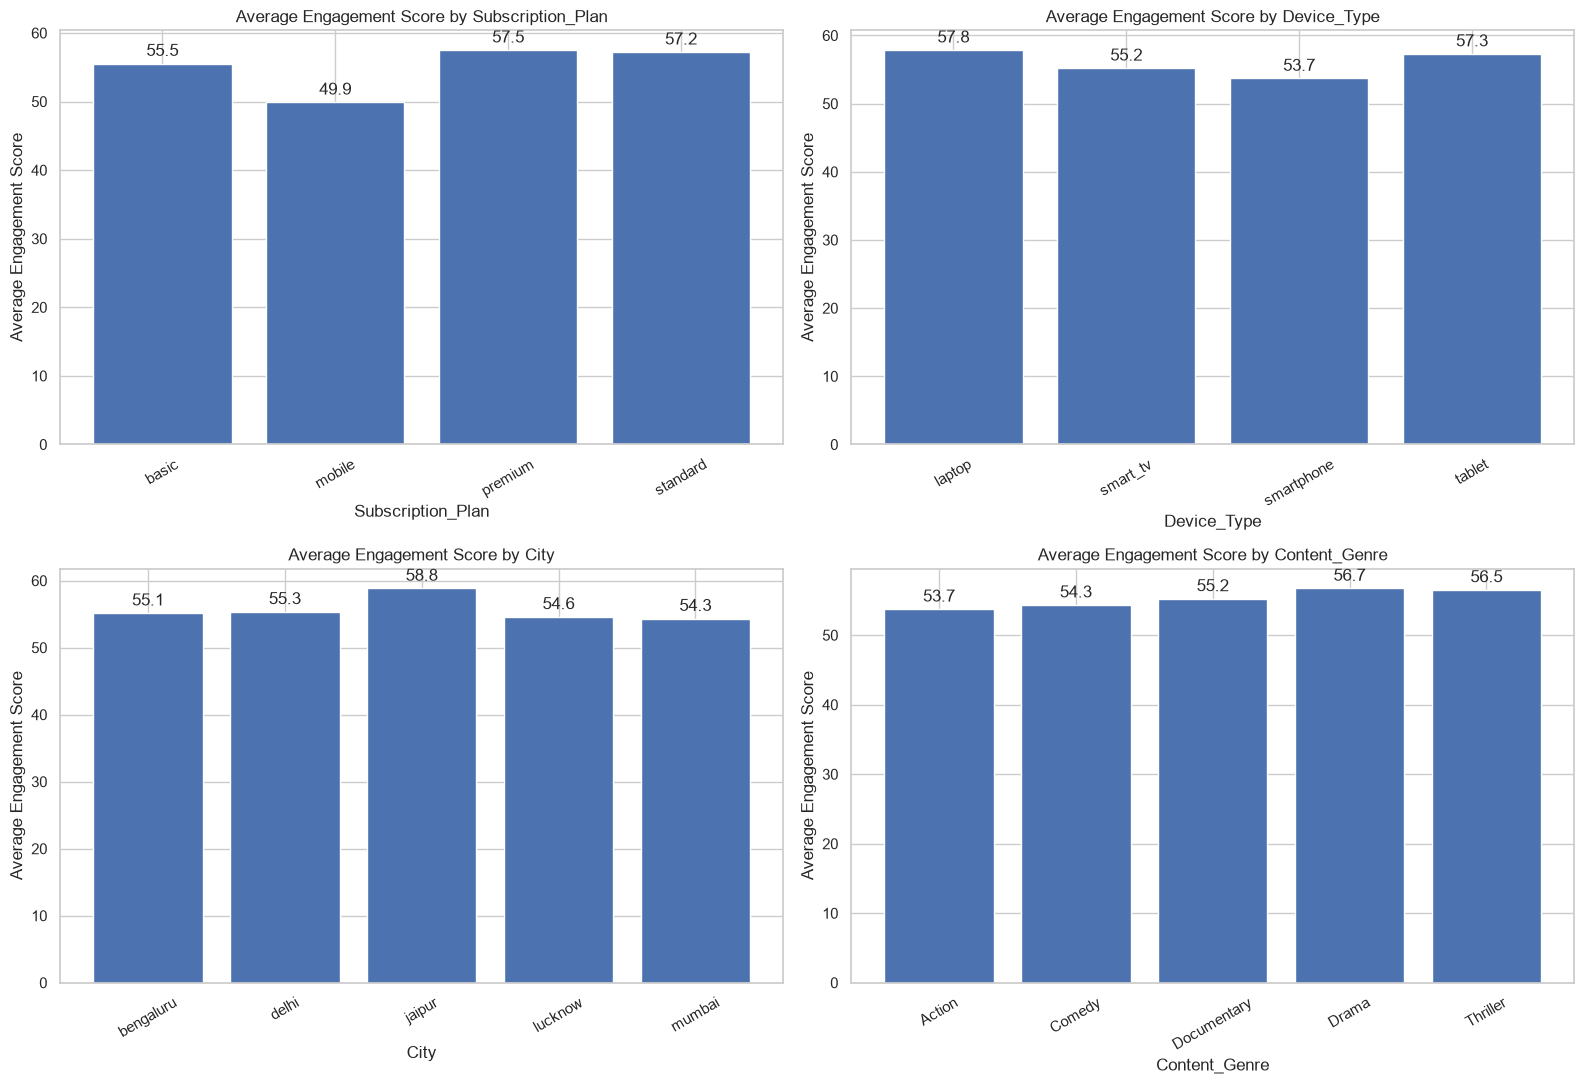

In [69]:
categories = [
    "Subscription_Plan",
    "Device_Type",
    "City",
    "Content_Genre"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes = axes.flatten()

for i, column in enumerate(categories):

    group_data = df.groupby(
        column,
        observed=True
    )["Engagement_Score"].mean().dropna()

    bars = axes[i].bar(
        group_data.index.astype(str),
        group_data.values
    )

    axes[i].set_title(
        "Average Engagement Score by " + column
    )

    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Average Engagement Score")

    axes[i].tick_params(
        axis="x",
        rotation=30
    )

    # Display values above bars
    axes[i].bar_label(
        bars,
        fmt="%.1f",
        padding=3
    )

plt.tight_layout()

plt.savefig(
    "04_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()